# E61: Did the Qwen fine-tunes truly learn, and do the readings see what training saw?


## The answer

The Qwen fine-tunes trained under half-precision rounding that hid their first small steps, while every reading used full precision. After four steps on the model's own answers, held-out loss reads 0.441 at full precision and 0.055 as training saw it. Final states agree well enough to keep. Every further check with a filed rule passed, and the one reading that beats random changes holds. Whether it measures more than size is still open. The learning rates themselves have not been tested yet.


## What we were trying to test

The user asked that the synthetic fine-tunes truly learn, at the right rates. An audit of the saved files found no fault in the data or the loss. It did find that training records and held-out readings of the same state disagreed by a factor of eight. That led to one test.

**Why rounding might do this.** Training keeps full-precision weights but runs its forward under bf16 autocast, which rounds each weight to a grid before use. The original model W0 was stored in bf16, so it sits exactly on that grid. An update smaller than half a grid step then rounds back to W0, and training cannot see it. Half a step is about 6e-5 at the median weight. Every reader of a saved state used full precision.

**The test.** No training. We read saved states three ways, on the same rows. The readers vary; the state and the rows are held fixed.
- *Full precision:* how every earlier reading was taken.
- *Autocast:* the forward training used.
- *Rounded:* weights rounded to bf16, then a full-precision forward. This separates the weights' rounding from the activations' precision.

The states come from three fine-tunes. One trained on the model's own answers, one on human GSM8K solutions, and one on an answer template the model already follows when prompted. We also generated answers at full precision from a few states.

**The five checks.** The audit then named five things never compared. Each ran on saved states, with a rule filed first. They read the decomposition's masked KL on 128 maths rows. Each cell below is a KL per position from the changed model to a masked one:
- K0: the original model against its own masked version.
- K00: the original subcomponents and original masks.
- K01: the original subcomponents, masks recomputed by Γ on the changed model.
- K10 and K11: the same two with the least-squares split applied to the subcomponents.

The **direct share** is (K00 − K10) / (K00 − K11): the part of the removable error taken out by changing only the subcomponents. The **re-gating share** is (K00 − K01) / (K00 − K11): the part taken out by recomputing only the masks. Both read 0 if that move does nothing and 1 if it does everything. The references are two random weight changes, one Gaussian and one on the alive subcomponents. E57 is the earlier experiment that read saved fine-tunes this way, and its measure of size is K00 − K0.


## What we expected, and why

If rounding was hiding the update, the audit expected the own-answers state after four steps to read 0.05 to 0.07 under autocast and on rounded weights. At full precision it was on record at 0.441. A reading of 0.30 or more would have ruled rounding out. It expected the readers to agree at step 100, because by then the update is far larger than the grid.

For the five checks, we expected no floor from Γ's own bf16 cast at a very small change. The direct share had no filed direction: the audit's hand estimate said the mask path might be as large as the direct one. The other three had no expected answer beyond their filed rules.


In [1]:
from pathlib import Path
from IPython.display import Image, display
FIG = Path("../experiments/qwen_recipe/figures")
def show(name):
    display(Image(filename=str(FIG / name), width=820))


## What we observed

### Does rounding hide the early update from training?


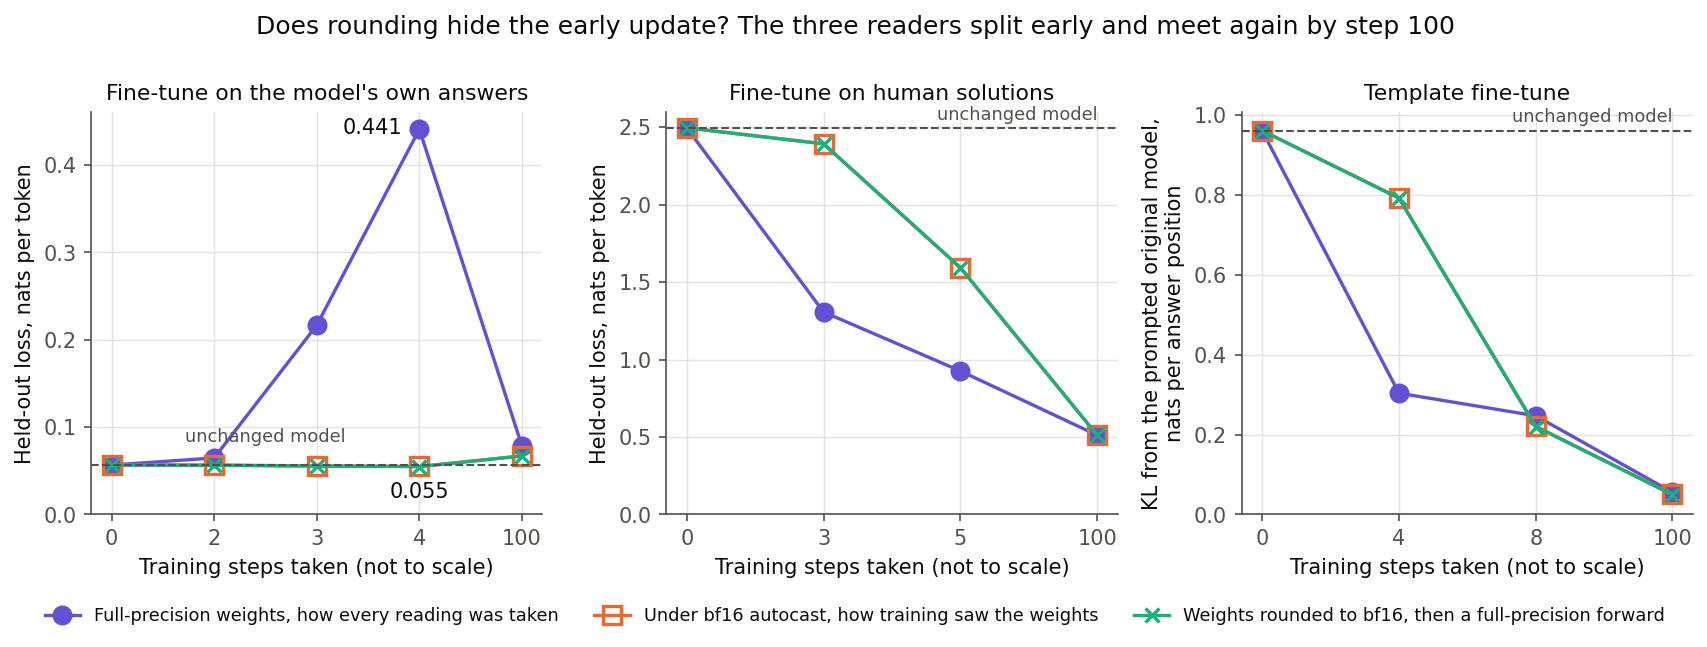

In [2]:
show("readers.png")


**Reading it.** Yes, for the states read. The worst case is the own-answers fine-tune after four steps. It reads 0.441 at full precision, and 0.055 both under autocast and on rounded weights, on the same rows. Both pass the filed line of 0.10, so weight rounding alone is enough; activation precision is not needed to explain it. Autocast and rounded stay within 0.002 of each other at every state. On the unchanged model all readers agree within 0.002, and rounding changes none of its entries.

At step 100 the three readers agree within the filed tolerance of 0.03 on all three fine-tunes. The agreement is weakest on the own-answers run. Its loss sits 0.022 above the unchanged model at full precision and 0.011 above under autocast, so the tolerance is larger than the whole rise.


### Do the two versions of a state give the same answers?


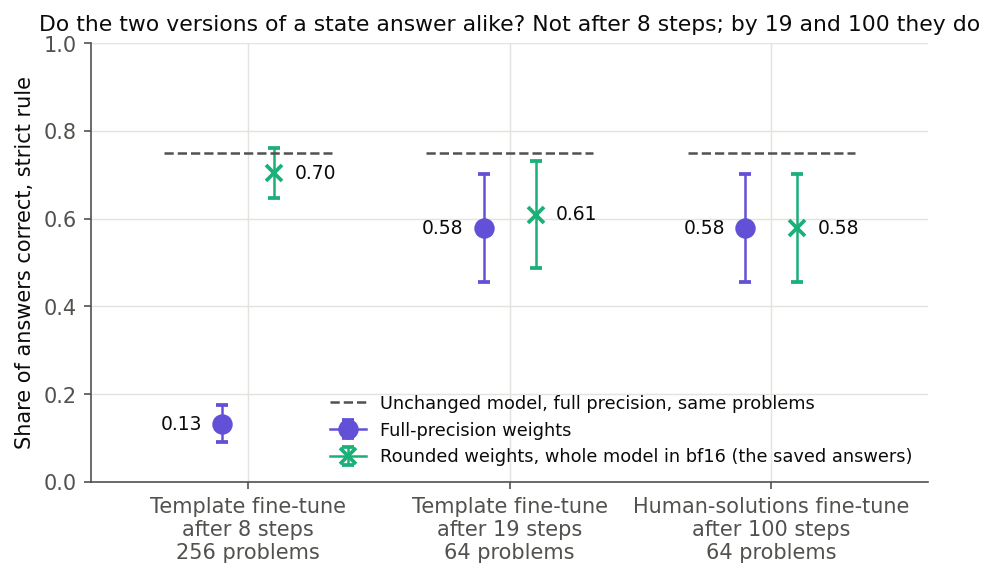

In [3]:
show("answers.png")


**Reading it.** Not early. The template fine-tune after 8 steps gets 0.13 of answers correct on full-precision weights and 0.70 on rounded ones. The unchanged model gets 0.75. The rounded answers come from a whole bf16 model, so this comparison mixes rounded weights with bf16 activations. So the saved answers at that step describe a different model from the one every decomposition reading holds. Neither form follows the template at step 8, so that state had not learned it by behaviour. By 19 steps the two forms agree within noise on 64 problems, and both follow the template on 0.95 of answers. The human-solutions fine-tune at step 100 reads 0.58 in both.


## Which earlier claims this touches

Checked means read in code, or measured here. Inferred means argued and not measured. Filed predictions are not edited.

| claim | what happens to it | how known |
|---|---|---|
| Ten-step fine-tune without warm-up, step 1 | Stands. Adam's first step uses the gradient at W0 | checked in code |
| Same run, step 10, and readings of it | Stands as a reading. Describe it as ten steps, the first five or so blind | inferred: this run was not read three ways |
| Bad-placement verdict on that update | Stands. It compares placements of one fixed update | checked in code |
| Direct and re-gating shares of saved states | Stand as readings of real full-precision states; how those states were reached changes | checked for the human-solutions state; invented facts not read three ways |
| Early "learned" flags, steps 2 to 12 | Do not stand as behaviour | measured at template step 8; inferred for the rest |
| "Invented facts at step 12 recall 2%" | Carries the same caution | inferred |
| Own-answers fine-tune "never learned" | Withdrawn as a statement about learning. The filed rule stays scored as filed | measured below |
| The 67M line | Looks unaffected: its checkpoint is full precision, so W0 is off the grid | inferred, not measured |
| No separation by the re-gating share | Not touched by rounding, which we do not offer as a cause: the random changes were never trained | see the last figure |


## The five checks

| check | what varied, what was held fixed | filed rule | result |
|---|---|---|---|
| Γ's cast at a tiny change | W0 plus a thousandth of the ten-step update; same 128 rows | K01 − K0 at most 0.005 nats, fewer than 500 switched on | −0.00003 and 133: no floor worth reading |
| Row format | whole problems against packed rows; W0 fixed | ratio of K0 within 1.5 | 0.056 against 0.070, ratio 0.81: same reading |
| Direct share with original masks | how masks were read; 16 rows, four changes | within 0.01 on all, same order | largest gap 0.0022: stands |
| Three sizes | six changes; 128 maths rows | a table, no threshold | below |
| Own-answers gain | full-precision weights; 1,319 problems | gain at least 0.03 and two standard errors above 0 | +0.037, se 0.011: survives |

### Does keeping the masks truly original change the direct share?


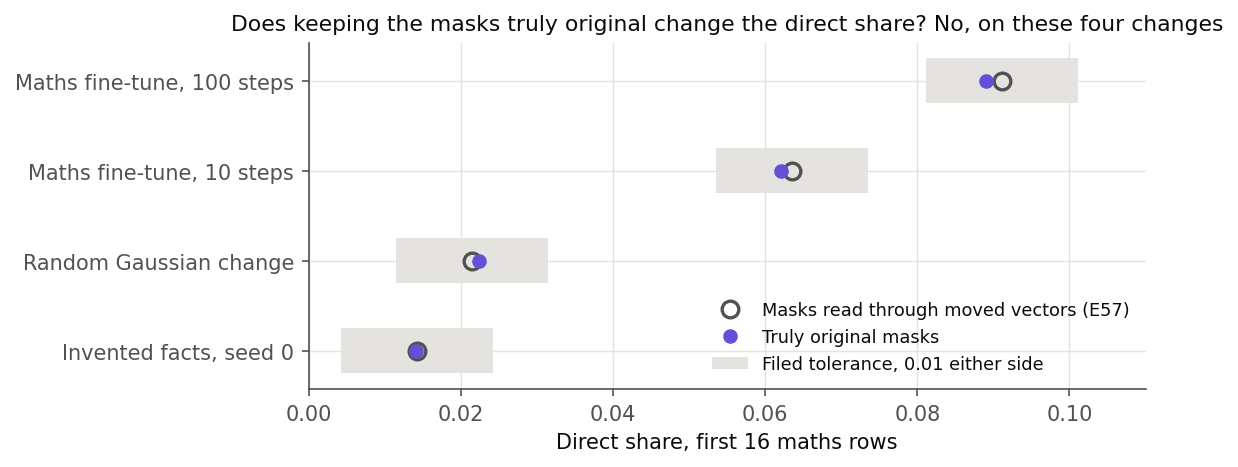

In [4]:
show("masks.png")


**Reading it.** No. The earlier reading computed K10's masks through the moved read vectors, though its prose called them original. Masks from the unmoved subcomponents give shares within 0.0022 of the earlier ones, in the same order. The 100-step maths fine-tune reads 0.089 against 0.091, and the Gaussian change 0.022 against 0.021. This is 16 rows and four changes; the 128-row reading with original masks has not run, and the next job uses this definition.

### Does the direct share rise with size? It depends on the measure


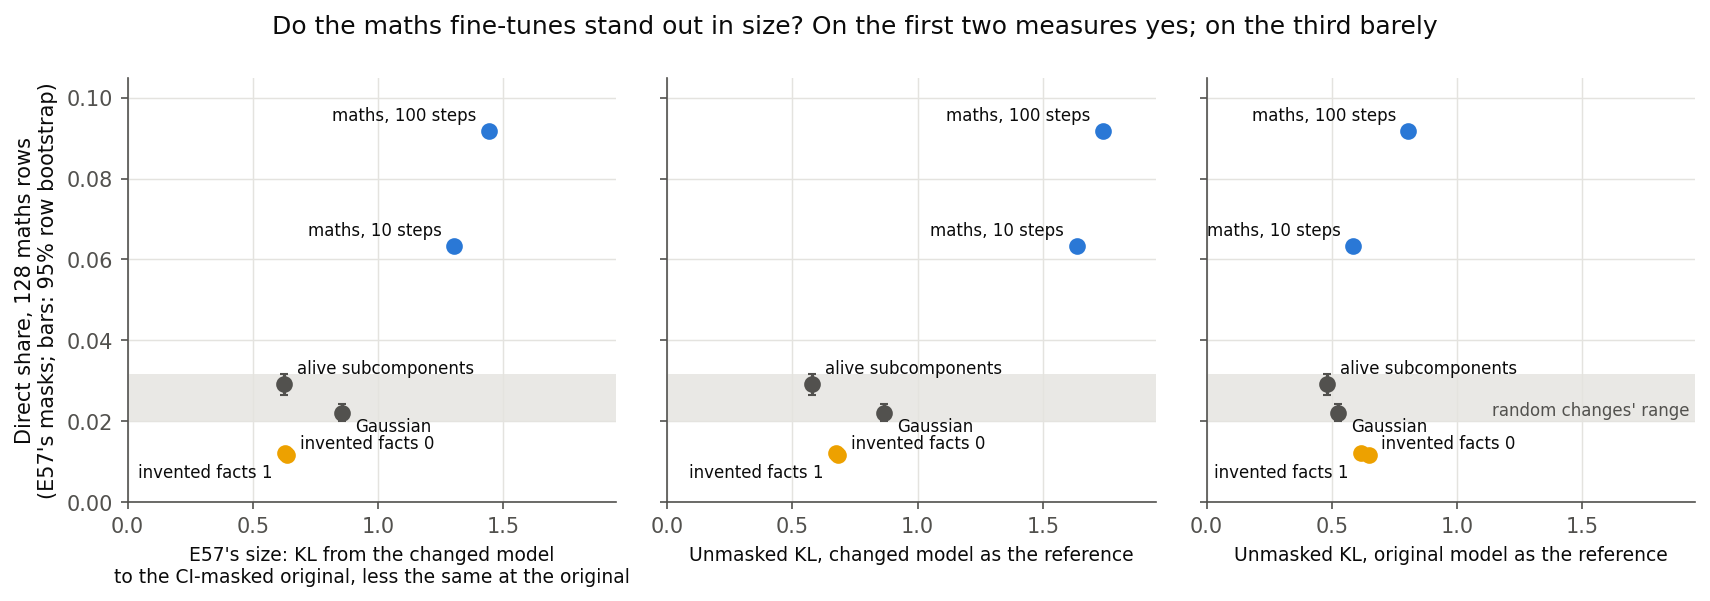

In [5]:
show("sizes.png")


**Reading it.** Open. The figure holds direct share on its vertical axis and changes only the measure of size. E57's measure and the unmasked KL with the changed model as reference tell one story. On both, the maths fine-tunes are 1.5 to 2 times the size of anything else, so their higher share could be size. The unmasked KL with the original model as reference tells another. There the 100-step run leads by only a quarter, and the ten-step run at 0.58 sits below invented facts at 0.65 with five times its share. So size neither explains the gap nor is ruled out, because no run has varied size with the kind of change held fixed. Neither measure is shown to be the right one. Invented facts read below both random changes; that value is unexplained.

### Does the own-answers gain survive full precision?


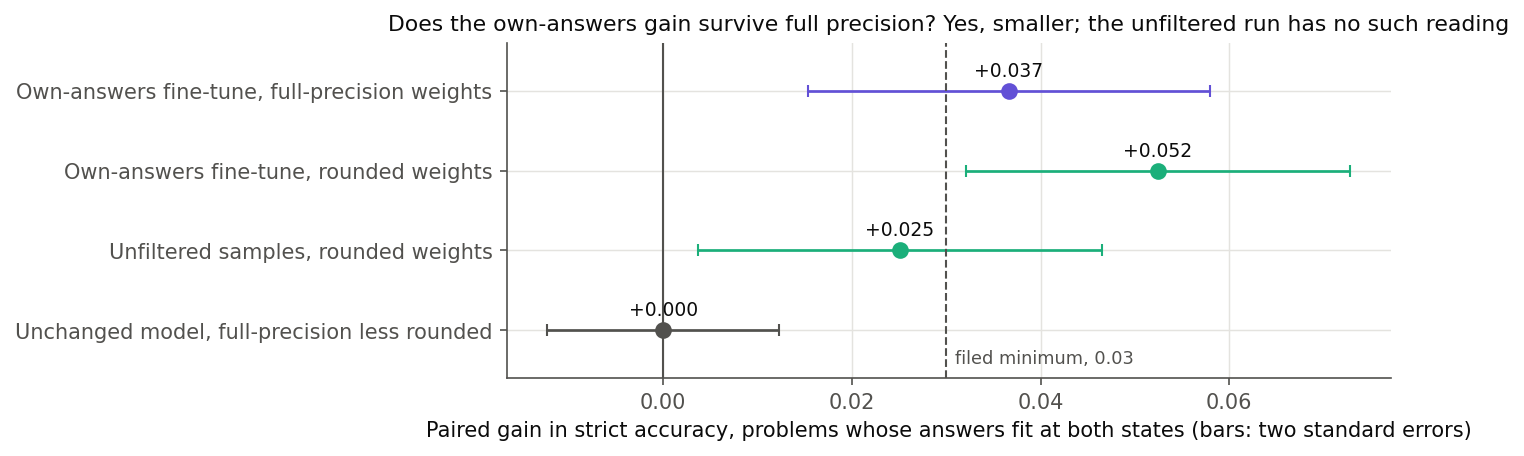

In [6]:
show("own_gain.png")


**Reading it.** Yes, and it is smaller. The paired accuracy gain over the unchanged model reads 0.037 at full precision against 0.052 on rounded weights. It is read on problems whose answers fit at both states, and it clears the filed 0.03. So "never learned" was a statement about one loss rule, and it is withdrawn as a statement about learning. Whether the gain beats the fine-tune on unfiltered samples is not settled: that run reads 0.025 on rounded weights and has no full-precision reading. The state read here was trained under rounding, so this is not yet what a full-precision run would reach. The bottom row is the unchanged model read both ways: 715 answers differ and the accuracy does not move.


## Settled from saved files

### Why does every change seem to overlap every reference set?


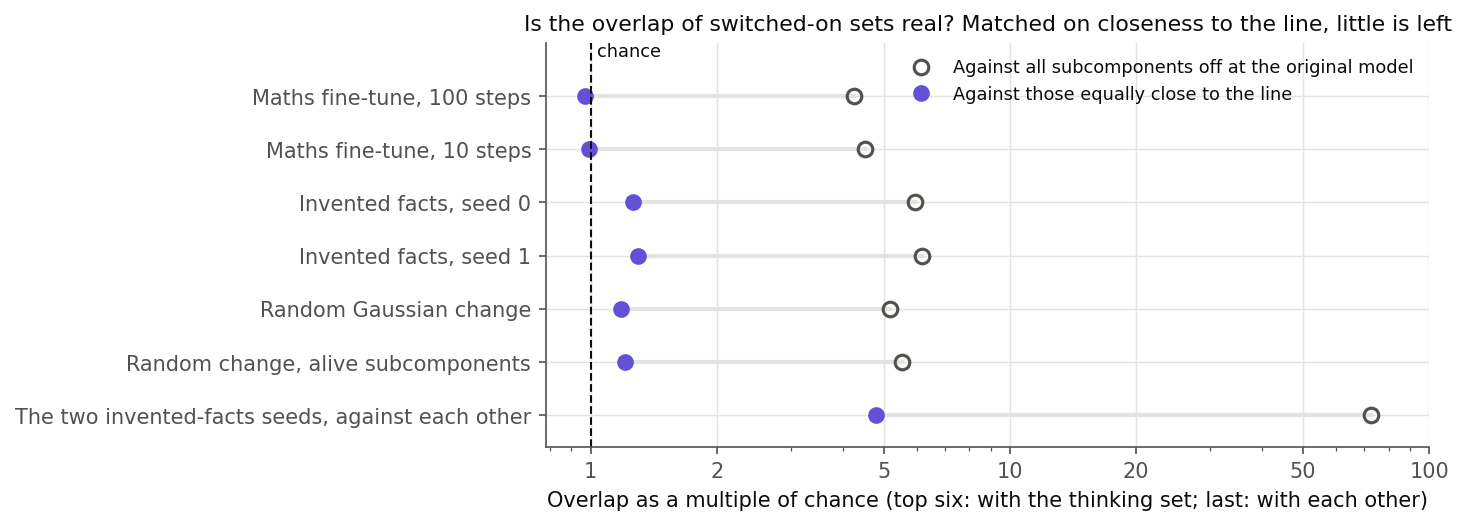

In [7]:
show("near_threshold.png")


**Reading it.** Mostly because of closeness to the line. A subcomponent counts as switched on when its causal importance passes 0.01 on at least 1% of positions. Of those a change switches on, 0.85 to 0.96 were already on for 0.5% to 1% of positions at the original model. Matched on that closeness, overlap with the thinking set falls from four to six times chance to about 1.0 to 1.3 times. The overlap's own control, the two invented-facts seeds against each other, falls from 72 to 4.8. Switching runs both ways too: the ten-step update switches on 5,730 and off 6,152. So these sets look like one side of jitter at the line, and the filed overlap null cannot fail. Bins and sites were not combined in this matching.

### Could the re-gating share have read low?


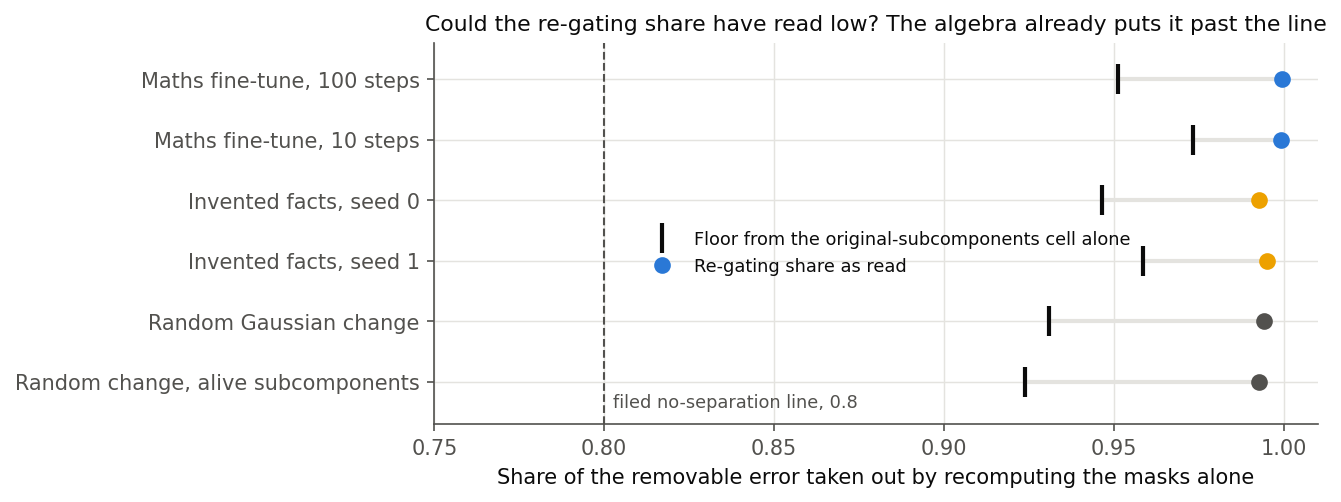

In [8]:
show("regating_floor.png")


**Reading it.** No. Whenever K11 is at or above K0, the share cannot fall below one minus K01 − K0 over K00 − K0. That floor alone is 0.92 to 0.97 across the six changes, past the filed line of 0.8. So the reading has no power to separate kinds of change at this scale, and that verdict stands. That K01 sits near K0 is measured, not forced. Rounding is not offered as its explanation, since the random changes never saw training.


## What we learned

Early states of these fine-tunes are not what their labels said, because training could not see them. That is confirmed for the readings listed, and not tested elsewhere. So before any comparison of small updates through the decomposition, the fine-tunes need retraining with the readers' forward. Final states are usable. `GOALS.md` asks whether a simple map fails because training teaches something new. This model still has no reading that separates the two cases: the direct share survives its checks, but it may only measure size.

The user's question about rates is not answered yet. No fine-tune has run at a second rate on a synthetic task.

## How compelling is the evidence

The rounding rests on one run's state on one set of rows for its filed verdict, and on nine other states read the same way. It is strong because the numbers moved by a factor of eight on one change of reader. The answers at 19 and 100 steps use 64 problems, with a standard error near 0.06. Each state is one seed. The original-masks check is 16 rows. The sizes are maths rows only, so each fine-tune's size on its own task is not here. The tiny-change check reads jitter in bf16 Γ, not its bias.

## Surprises

- **Teacher-forced agreement hid a large gap in answers.** At template step 8 the KL reads 0.247 at full precision and 0.221 under autocast. Yet answers differ, 0.13 against 0.70 correct. Not tested why.
- **Step 100 agrees less on maths rows.** On the own-answers run, maths KL reads 0.079 at full precision and 0.048 under autocast. No rule reads this.
- **E57's size follows the unmasked KL with the changed model as reference,** within about a quarter on all six changes, though nobody filed that.
- **A filed expected value missed.** At the tiny change K00 − K0 read 0.0002, where the filing said under 0.0001. The filing assumed a square law, which a KL to the masked model need not follow. Switched on and switched off are both exactly 133; the code computes them separately, and we did not look further.

## What next

Run E61 Parts 1 and 2 of `reports/plans/2026-11-02_plan_e61-direct-share-size.md`: fine-tunes with a full-precision forward at measured rates, then the direct share against size.


## Departures from the literature

- **Mixed precision.** Standard training uses a bf16 autocast forward, from memory and not checked here. The saved states used it; the next part replaces it with a full-precision forward, because the first steps are what we read.
- **Rate and warm-up.** The cited 1e-5 with warm-up ratio 0.1 has no copy in the repo, and a ratio written for long runs was applied to 100 steps. Treat it as unsourced for this length.
- **Masks from another model.** VPD computes masks from the model being decomposed; K00 and K10 use the original model's. The original-mask check removes the moved read vectors from that path, and nothing else.
- **Direct and re-gating shares, K00 − K0 as size, and the threshold bins** are this project's; no source defines them.
- **Switched on** adds "on at least 1% of positions" to VPD's alive threshold of a mask above 0.01.
- **Row format.** The fit read documents with per-document attention and position resets; the 128 packed rows have neither.

## Scorecard

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| R1 autocast | rounding hides own step 4 | at most 0.10 | 0.0549 | confirmed |
| R1 rounded | same | at most 0.10 | 0.0548 | confirmed |
| R2 own | readers agree at step 100 | excess at most 0.03 | 0.0112 | holds |
| R2 human solutions | same | same | −0.0011 | holds |
| R2 template | same | same | 0.0052 | holds |
| R3 | generation at full precision | description | see report | no verdict |
| tiny | no floor from Γ's cast | gap at most 0.005, under 500 on | −0.00003, 133 | passes |
| k0 | row format does not change K0 | ratio within 1.5 | 0.81 | passes |
| sizes | three measures | table | see report | no verdict |
| gen | own gain survives | at least 0.03, two se above 0 | +0.0366, se 0.0107 | passes |
| k10 | masks do not change the reading | within 0.01, same order | 0.0022, same | passes |

## Not run

- Any training with a full-precision forward, so whether it reaches the same states.
- A rate grid on any synthetic task.
- The three readers on the ten-step update, invented facts, or the unfiltered run.
- Full-precision generation of invented facts, or of states from the unfiltered run.
- The direct share with original masks on all 128 rows, or on the alive-subcomponents change and the second invented-facts seed.
- Random changes scaled to the largest fine-tune's size, or a smaller state of that fine-tune.
- Full-precision Γ against bf16 Γ directly at a large change.
- The template fine-tune through the decomposition.
- The 67M's weight magnitudes and flip fraction.

Provenance: L40, cluster, $0. Job 48367 for the readers; 48473, 48494, 48506, 48538 and 48624, and 48645, 48675, 48721 and 48747 for the checks. Results in `experiments/qwen_recipe/results/`. Full record: `reports/analyses/2026-11-02_analysis_e61-recipe-checks.md`.
